Loading metadata...


Crossmatch: 100%|██████████| 2261/2261 [00:00<00:00, 30964.84it/s]


Objects with CSV + light curve: 468


Processing: 100%|██████████| 468/468 [00:03<00:00, 151.03it/s]


Valid objects: 468


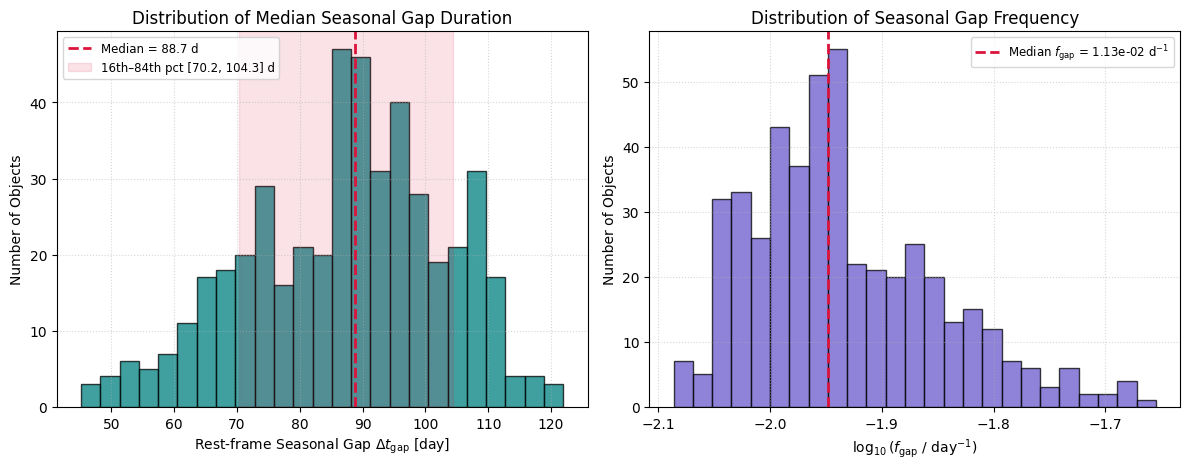

Grid: 31 bins, f_min=5.533e-04, f_max=0.714


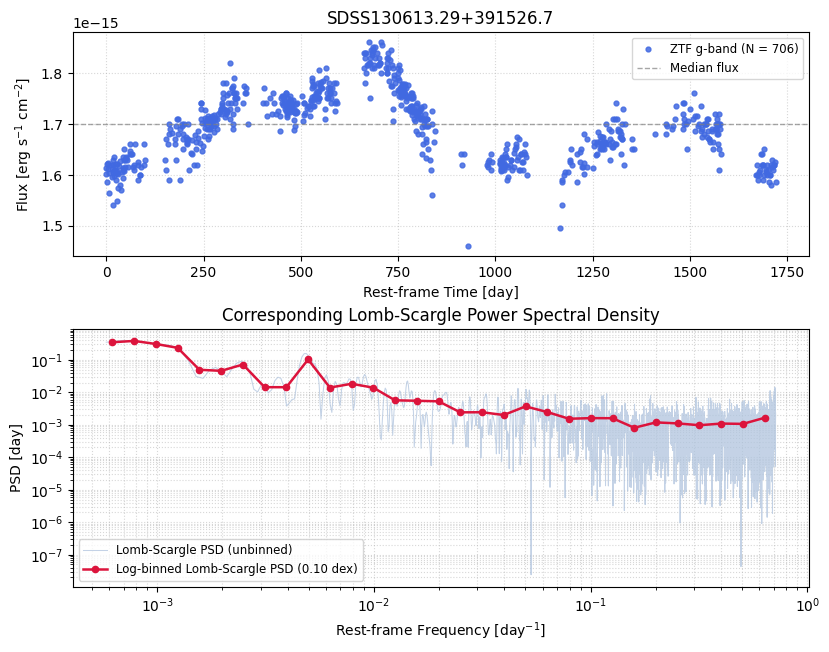

Lomb-Scargle: 100%|██████████| 468/468 [00:01<00:00, 442.03it/s]


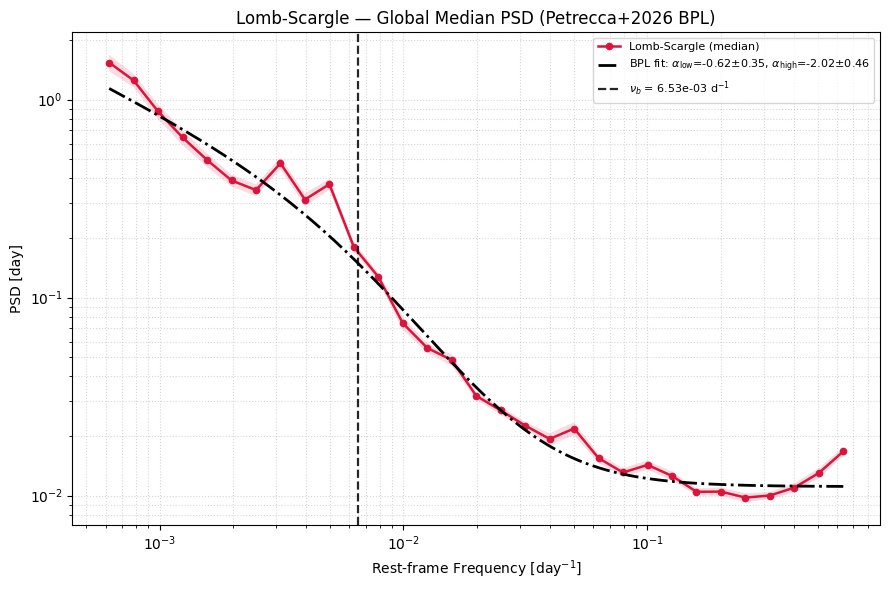


Computing ensembles...


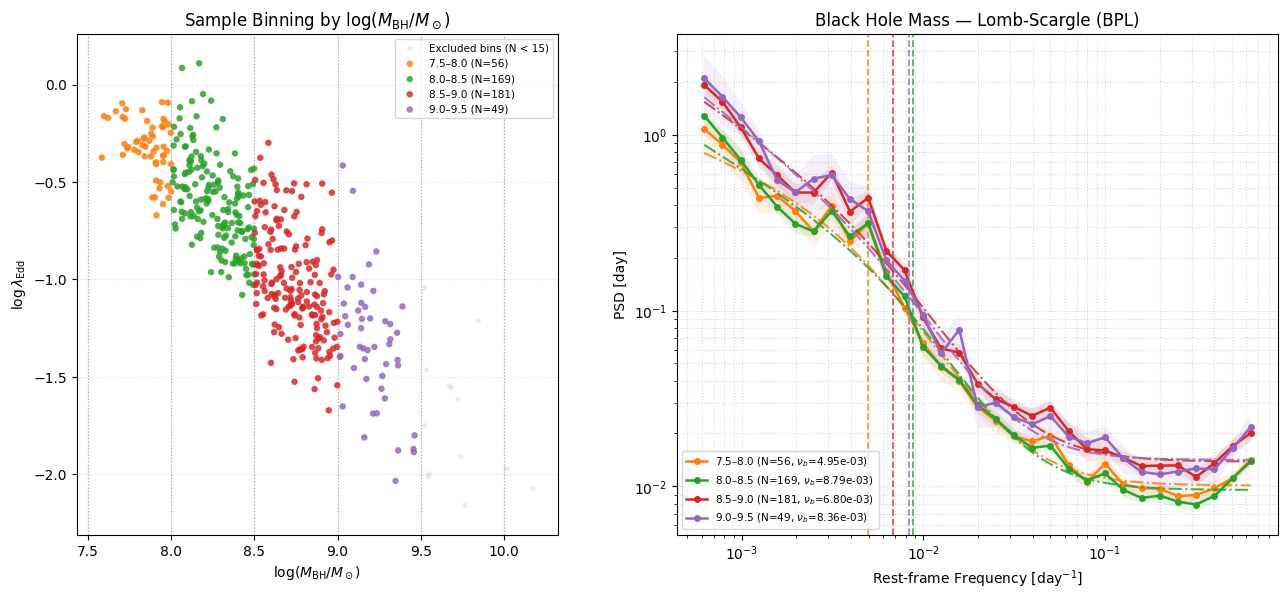

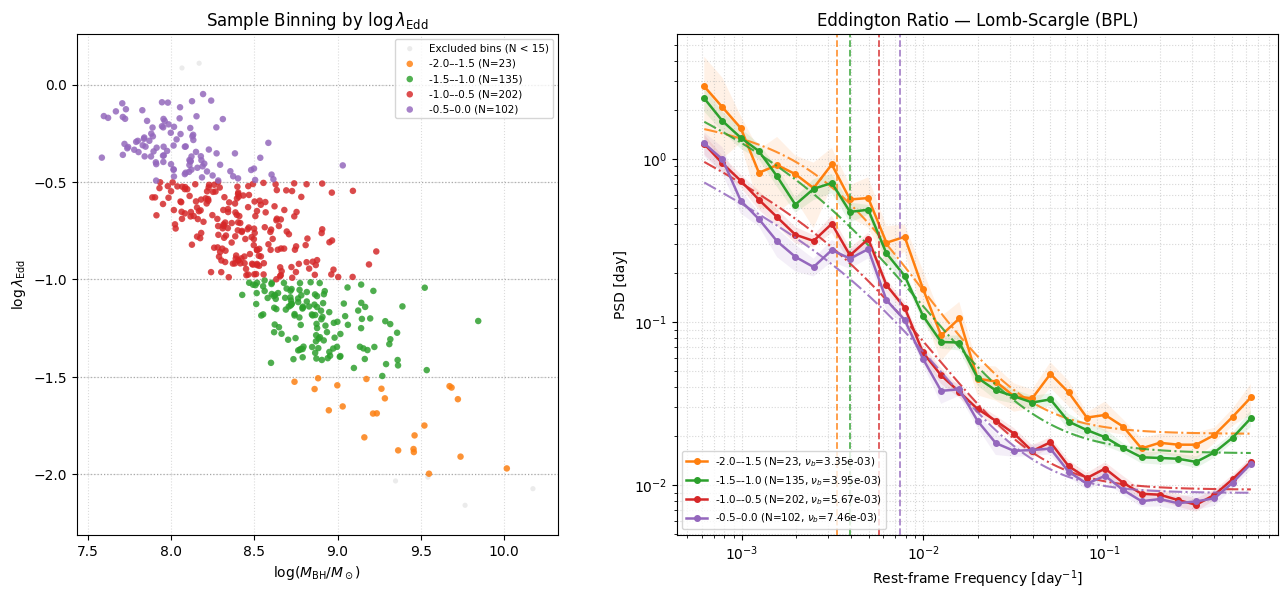

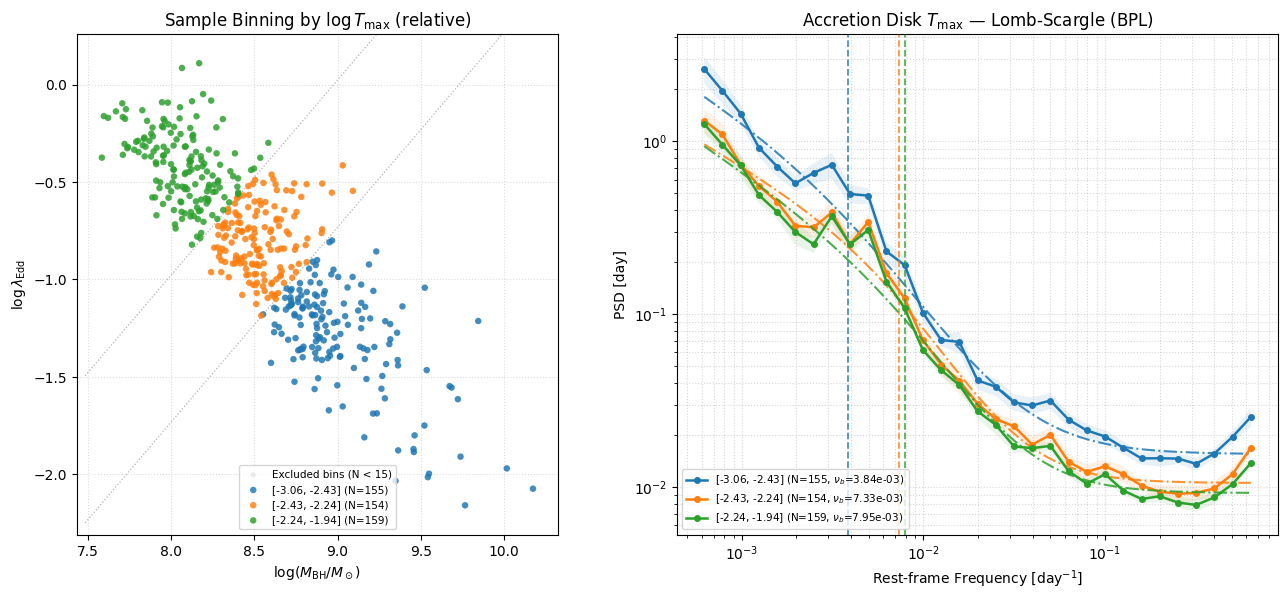

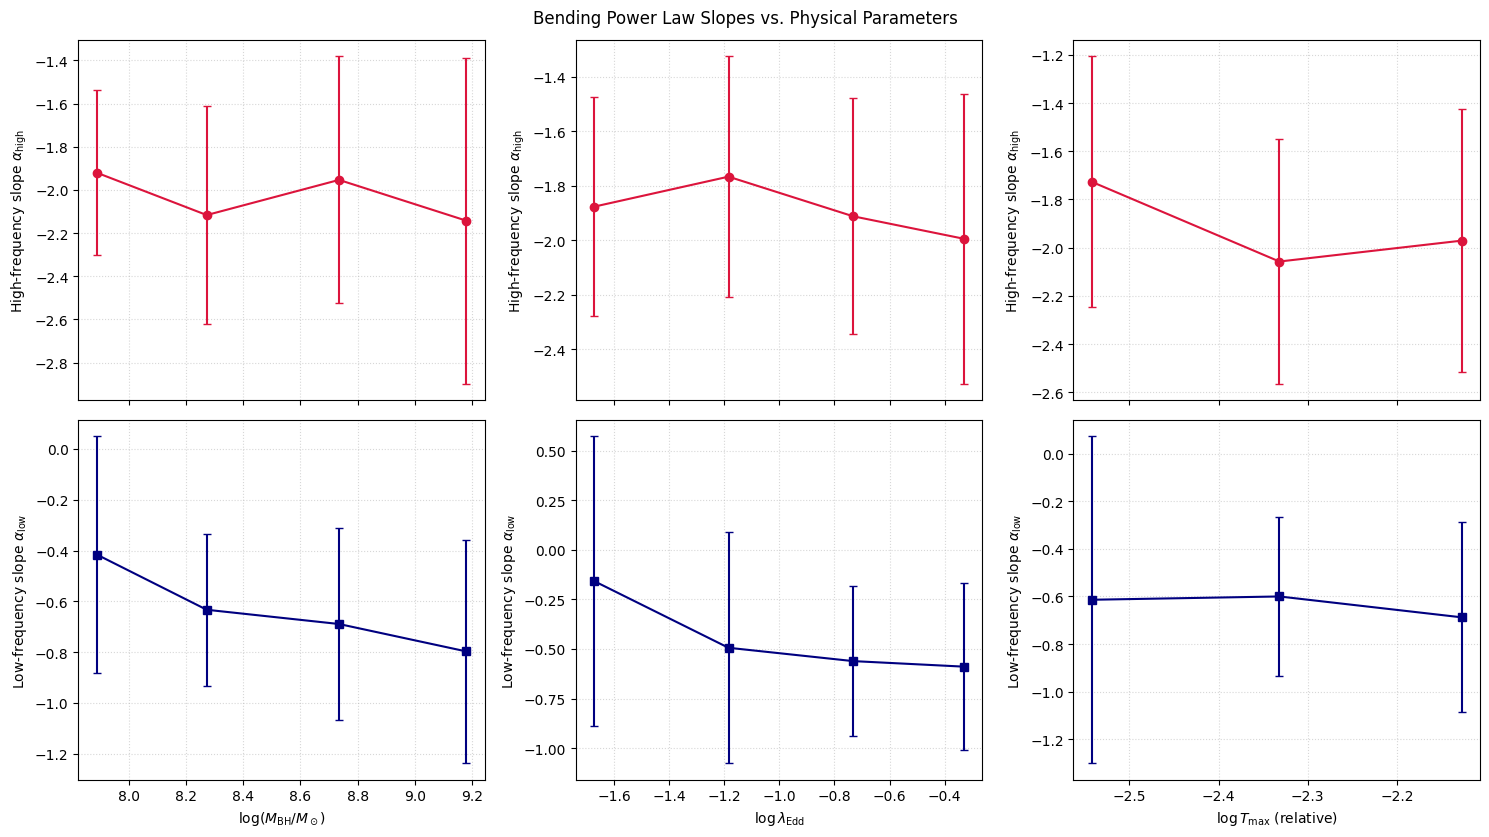


FINAL SUMMARY (LOMB-SCARGLE + FULL-CURVE BPL)
Valid objects: 468
Median seasonal gap (rest-frame): 88.7 d (f_gap = 1.127e-02 d^-1)

Global ensemble fit:
  alpha_low  = -0.615 +/- 0.355
  alpha_high = -2.015 +/- 0.459
  nu_b       = 6.53e-03 +/- 6.66e-03 (in_range)

Report: plots_LS_BPL_g\report_LS_BPL.txt
CSV:    plots_LS_BPL_g\fits_BPL.csv
Plots:  seasonal_gaps_histogram.png, example_lc_psd.png, global_psd_BPL.png, ensemble_mass.png, ensemble_edd.png, ensemble_tmax.png, params_trends_BPL.png


In [1]:
# =============================================================================
# FINAL PIPELINE — Lomb-Scargle + Petrecca+2026 Bending Power Law (Full Curve)
#
# DECISIONS:
# - Lomb-Scargle without dy (confirmed bug #11939: psd+dy inflates PSD).
# - Robust rescaling: \int P df = Var(flux_norm).
# - Full-curve Bending Power Law from Petrecca+2026 (Eq. 3) with free
#   alpha_low, free alpha_high, and unbounded bending frequency nu_b.
# - Includes a histogram of measured rest-frame seasonal gaps across objects.
# - Includes an example two-panel plot showing the unnormalized light curve
#   (top, with SDSS_NAME_1 identifier) of the highest-S/N well-sampled quasar
#   and its corresponding Lomb-Scargle PSD (bottom).
# - Side-by-side ensemble figures: left panel shows individual objects colored
#   by bin in the (log M_BH, log lambda_Edd) plane; right panel shows the
#   matching color-coded ensemble PSDs and BPL fits.
# - Marks nu_b with a vertical dashed line when inside the observed range,
#   and appends '[out_range]' to the legend only when outside.
# - Restricts ensemble plots to bins with at least 15 objects (removes < 15).
# =============================================================================

import os
import glob
import numpy as np
import pandas as pd
from tqdm import tqdm
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from astropy.timeseries import LombScargle
import warnings
warnings.filterwarnings('ignore')

# =============================================================================
# CONFIGURATION
# =============================================================================
BASE_DIR = r"ztffp_final_data_2025"
CSV_META = r"Cross_15_luiz.csv"
BAND = 'g'
PLOTS_DIR = f"plots_LS_BPL_{BAND}"
os.makedirs(PLOTS_DIR, exist_ok=True)
REPORT_PATH = os.path.join(PLOTS_DIR, "report_LS_BPL.txt")

CADENCE_DAYS = 0.70
F_MAX_NYQUIST = 1.0 / (2.0 * CADENCE_DAYS)   # ~0.714 d^-1
Z_MIN, Z_MAX = 0.4, 0.5
TARGET_DEX_STEP = 0.10

# Seasonal gap classification threshold (observer frame)
MIN_SEASONAL_GAP_OBS_DAYS = 60.0

# Bin edges kept identical to original pipeline
mass_edges = [7.0, 7.5, 8.0, 8.5, 9.0, 9.5, 10.0]
edd_edges = [-2.5, -2.0, -1.5, -1.0, -0.5, 0.0, 0.5]

MIN_OBJS_PER_BIN = 15          # Remove ensembles with fewer than 15 objects
MIN_CONTRIB_GLOBAL = 11
MIN_CONTRIB_ENSEMBLE = 11
N_BOOTSTRAP = 100
cmap = plt.get_cmap('tab10')

with open(REPORT_PATH, 'w', encoding='utf-8') as f:
    f.write("REPORT: Lomb-Scargle + Bending Power Law (Petrecca+2026, Full Curve)\n")
    f.write("=" * 80 + "\n\n")

# =============================================================================
# FUNCTIONS
# =============================================================================
def coadd_nightly(t_obs, f_obs, f_err):
    """Inverse-variance weighted nightly coaddition (Stone+2022)."""
    day_ids = np.floor(t_obs).astype(int)
    unique_days = np.unique(day_ids)
    t_d, f_d, e_d = [], [], []
    for d in unique_days:
        mask = (day_ids == d)
        if np.sum(mask) == 1:
            t_d.append(t_obs[mask][0])
            f_d.append(f_obs[mask][0])
            e_d.append(f_err[mask][0])
        else:
            w = 1.0 / (f_err[mask] ** 2 + 1e-30)
            t_d.append(np.mean(t_obs[mask]))
            f_d.append(np.sum(w * f_obs[mask]) / np.sum(w))
            e_d.append(1.0 / np.sqrt(np.sum(w)))
    return np.array(t_d), np.array(f_d), np.array(e_d)


def measure_seasonal_gap(t_obs, z, min_gap_obs=MIN_SEASONAL_GAP_OBS_DAYS):
    """
    Measure median seasonal gap duration in rest-frame days and its
    corresponding frequency f_gap = 1 / dt_gap_rest for an object.
    """
    if len(t_obs) < 2:
        return np.nan, np.nan
    dt_obs = np.diff(t_obs)
    seasonal_gaps_obs = dt_obs[dt_obs >= min_gap_obs]
    if len(seasonal_gaps_obs) == 0:
        return np.nan, np.nan
    dt_gap_rest = float(np.median(seasonal_gaps_obs)) / (1.0 + z)
    f_gap_rest = 1.0 / dt_gap_rest
    return dt_gap_rest, f_gap_rest


def calibrated_ls_psd(t_rest, flux_norm, f_min, f_max):
    """Lomb-Scargle PSD without dy, rescaled so that integral(P df) = Var(y)."""
    ls = LombScargle(t_rest, flux_norm, fit_mean=True, center_data=True)
    freqs, p_psd = ls.autopower(normalization='psd',
                                minimum_frequency=f_min,
                                maximum_frequency=f_max,
                                samples_per_peak=5)
    var_target = float(np.var(flux_norm))
    if len(freqs) > 1:
        integral = float(np.trapz(p_psd, freqs))
        if integral > 0 and np.isfinite(integral):
            p_psd = p_psd * (var_target / integral)
    return freqs, p_psd


def bin_to_log_grid(freqs, powers, bin_edges):
    """Average PSD values within logarithmically spaced frequency bins."""
    n_bins = len(bin_edges) - 1
    binned = np.full(n_bins, np.nan)
    inds = np.searchsorted(bin_edges, freqs, side='right') - 1
    valid = (inds >= 0) & (inds < n_bins) & np.isfinite(powers) & (powers > 0)
    if not np.any(valid):
        return binned
    bid, pw = inds[valid], powers[valid]
    sums = np.bincount(bid, weights=pw, minlength=n_bins)
    counts = np.bincount(bid, minlength=n_bins)
    mask = counts > 0
    binned[mask] = sums[mask] / counts[mask]
    return binned


def bpl_petrecca(f, norm, nu_b, alpha_low, alpha_high, noise):
    """Bending Power Law from Petrecca+2026 (Eq. 3) with free alpha_low and alpha_high."""
    diff = alpha_low - alpha_high
    return norm * (f ** alpha_low) * (1.0 + (f / nu_b) ** diff) ** (-1.0) + noise


def fit_bpl(freq, power, sigma=None):
    """
    Fit Petrecca+2026 BPL with free alpha_low, free alpha_high, and unbounded
    nu_b in (0, inf) across the provided frequency range.
    """
    mask = (power > 0) & np.isfinite(power) & (freq > 0)
    use_sigma = (sigma is not None) and np.any(np.isfinite(sigma) & (sigma > 0))
    if use_sigma:
        mask &= (sigma > 0) & np.isfinite(sigma)
    if np.sum(mask) < 6:
        return None

    f_fit, p_fit = freq[mask], power[mask]
    s_fit = sigma[mask] if use_sigma else None
    f_min_fit = float(f_fit.min())
    f_max_fit = float(f_fit.max())

    alpha_low_0 = -1.0
    alpha_high_0 = -2.5
    nu_b_0 = 0.5 * f_min_fit
    shape_0 = (f_fit ** alpha_low_0) * (1.0 + (f_fit / nu_b_0) ** (alpha_low_0 - alpha_high_0)) ** (-1.0)
    norm_0 = float(np.median(p_fit / np.maximum(shape_0, 1e-30)))
    noise_0 = 0.1 * float(np.min(p_fit))

    p0 = [max(norm_0, 1e-12), nu_b_0, alpha_low_0, alpha_high_0, noise_0]
    lower_bounds = [1e-20, 0.0, -5.0, -6.0, 0.0]
    upper_bounds = [np.inf, np.inf, 1.0, 0.5, np.max(p_fit)]

    try:
        popt, pcov = curve_fit(
            bpl_petrecca, f_fit, p_fit, p0=p0, sigma=s_fit,
            absolute_sigma=False, bounds=(lower_bounds, upper_bounds),
            maxfev=20000
        )
        diag_cov = np.diag(pcov)
        perr = np.where(np.isfinite(diag_cov) & (diag_cov >= 0),
                        np.sqrt(np.maximum(diag_cov, 0.0)), np.nan)
        nu_b_val = popt[1]

        if f_min_fit <= nu_b_val <= f_max_fit:
            nu_b_regime = 'in_range'
        else:
            nu_b_regime = 'out_range'

        return {
            'norm': popt[0], 'norm_err': perr[0],
            'nu_b': nu_b_val, 'nu_b_err': perr[1],
            'alpha_low': popt[2], 'alpha_low_err': perr[2],
            'alpha_high': popt[3], 'alpha_high_err': perr[3],
            'noise': popt[4], 'noise_err': perr[4],
            'f_min_fit': f_min_fit, 'f_max_fit': f_max_fit,
            'nu_b_regime': nu_b_regime
        }
    except Exception:
        return None


def median_bootstrap(matrix, n_boot=N_BOOTSTRAP):
    """Compute column-wise median and bootstrap standard deviation."""
    n = matrix.shape[0]
    if n < 2:
        return np.nanmedian(matrix, axis=0), np.zeros(matrix.shape[1])
    samples = []
    for _ in range(n_boot):
        idx = np.random.choice(n, n, replace=True)
        samples.append(np.nanmedian(matrix[idx, :], axis=0))
    samples = np.array(samples)
    return np.nanmedian(samples, axis=0), np.nanstd(samples, axis=0)


# =============================================================================
# LOAD + CROSSMATCH
# =============================================================================
print("Loading metadata...")
meta = pd.read_csv(CSV_META)
ra_cat = meta['RA'].values
dec_cat = meta['DEC'].values
logmbh_cat = meta['LOGMBH'].values
logedd_cat = meta['LOGLEDD_RATIO'].values
z_col = 'Z_DR16Q' if 'Z_DR16Q' in meta.columns else 'Z'
z_cat = meta[z_col].values

if 'SDSS_NAME_1' in meta.columns:
    sdss_names_cat = meta['SDSS_NAME_1'].astype(str).str.strip().values
elif 'SDSS_NAME' in meta.columns:
    sdss_names_cat = meta['SDSS_NAME'].astype(str).str.strip().values
else:
    sdss_names_cat = np.array(['Unknown'] * len(meta))

folders = [f for f in os.listdir(BASE_DIR)
           if os.path.isdir(os.path.join(BASE_DIR, f)) and "plots" not in f]

matched = []
for folder in tqdm(folders, desc="Crossmatch"):
    try:
        ra_f, dec_f = map(float, folder.split('_'))
    except Exception:
        continue
    dist = np.sqrt((ra_cat - ra_f) ** 2 + (dec_cat - dec_f) ** 2)
    idx = np.argmin(dist)
    if dist[idx] < 1e-4:
        z, m, e = z_cat[idx], logmbh_cat[idx], logedd_cat[idx]
        if np.isnan(m) or np.isnan(e) or np.isnan(z):
            continue
        if not (Z_MIN <= z <= Z_MAX):
            continue
        txts = glob.glob(os.path.join(BASE_DIR, folder, f"*_ztf_{BAND}_filtered.txt"))
        if txts:
            matched.append((folder, idx, txts[0]))

print(f"Objects with CSV + light curve: {len(matched)}")

# =============================================================================
# PROCESS OBJECTS + MEASURE SEASONAL GAPS
# =============================================================================
valid_data = []
for folder, idx, txt_path in tqdm(matched, desc="Processing"):
    try:
        df = pd.read_csv(txt_path).sort_values('mjd')
        if len(df) < 20:
            continue
        t_raw = df['mjd'].values
        f_raw = df['flux'].values
        err_raw = df['fluxe'].values if 'fluxe' in df.columns else np.zeros_like(f_raw)

        t_obs, f_obs, f_err = coadd_nightly(t_raw, f_raw, err_raw)
        if len(t_obs) < 15:
            continue

        z = z_cat[idx]
        dt_gap_rest, f_gap_rest = measure_seasonal_gap(t_obs, z)

        t_rest = (t_obs - t_obs.min()) / (1.0 + z)
        T_total = t_rest.max() - t_rest.min()

        f_med = np.median(f_obs)
        f_norm = (f_obs - f_med) / f_med

        raw_sdss = sdss_names_cat[idx]
        sdss_id = raw_sdss if raw_sdss.startswith("SDSS") else f"SDSS{raw_sdss}"

        valid_data.append({
            'folder': folder, 'txt_path': txt_path, 'sdss_id': sdss_id,
            't_rest': t_rest, 'f_obs': f_obs, 'f_err': f_err,
            'f_norm': f_norm, 'T_total': T_total, 'z': z,
            'LOGM': logmbh_cat[idx], 'LOGE': logedd_cat[idx],
            'dt_gap_rest': dt_gap_rest, 'f_gap_rest': f_gap_rest
        })
    except Exception:
        continue

print(f"Valid objects: {len(valid_data)}")
if len(valid_data) == 0:
    raise RuntimeError("No valid objects found.")

# =============================================================================
# HISTOGRAM OF MEASURED SEASONAL GAPS
# =============================================================================
dt_gaps_arr = np.array([d['dt_gap_rest'] for d in valid_data if np.isfinite(d['dt_gap_rest'])])
f_gaps_arr = 1.0 / dt_gaps_arr

dt_gap_med = float(np.median(dt_gaps_arr))
dt_gap_q16, dt_gap_q84 = np.percentile(dt_gaps_arr, [16, 84])
f_gap_med = float(np.median(f_gaps_arr))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

# Left: Rest-frame seasonal gap duration [days]
axes[0].hist(dt_gaps_arr, bins=25, color='teal', edgecolor='black', alpha=0.75)
axes[0].axvline(dt_gap_med, color='crimson', ls='--', lw=2,
                label=f'Median = {dt_gap_med:.1f} d')
axes[0].axvspan(dt_gap_q16, dt_gap_q84, color='crimson', alpha=0.12,
                label=f'16th–84th pct [{dt_gap_q16:.1f}, {dt_gap_q84:.1f}] d')
axes[0].set_xlabel(r'Rest-frame Seasonal Gap $\Delta t_{\mathrm{gap}}$ [day]')
axes[0].set_ylabel('Number of Objects')
axes[0].set_title('Distribution of Median Seasonal Gap Duration')
axes[0].legend(fontsize=8.5)
axes[0].grid(ls=':', alpha=0.5)

# Right: Corresponding rest-frame gap frequency [day^-1]
axes[1].hist(np.log10(f_gaps_arr), bins=25, color='slateblue', edgecolor='black', alpha=0.75)
axes[1].axvline(np.log10(f_gap_med), color='crimson', ls='--', lw=2,
                label=f'Median $f_{{\\mathrm{{gap}}}}$ = {f_gap_med:.2e} d$^{{-1}}$')
axes[1].set_xlabel(r'$\log_{10}(f_{\mathrm{gap}}\ / \ \mathrm{day}^{-1})$')
axes[1].set_ylabel('Number of Objects')
axes[1].set_title('Distribution of Seasonal Gap Frequency')
axes[1].legend(fontsize=8.5)
axes[1].grid(ls=':', alpha=0.5)

plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, 'seasonal_gaps_histogram.png'), dpi=200)
plt.show()

with open(REPORT_PATH, 'a', encoding='utf-8') as f:
    f.write("=== MEASURED SEASONAL GAPS (REST-FRAME) ===\n")
    f.write(f"Objects with measurable gaps (>= {MIN_SEASONAL_GAP_OBS_DAYS} d obs): "
            f"{len(dt_gaps_arr)}/{len(valid_data)}\n")
    f.write(f"Median dt_gap (rest-frame) = {dt_gap_med:.2f} d "
            f"(16th-84th pct: {dt_gap_q16:.2f} - {dt_gap_q84:.2f} d)\n")
    f.write(f"Median f_gap  (rest-frame) = {f_gap_med:.3e} d^-1 "
            f"(log10 f_gap = {np.log10(f_gap_med):.3f})\n\n")

# =============================================================================
# GLOBAL LOG FREQUENCY GRID
# =============================================================================
f_min_global = 1.0 / max(d['T_total'] for d in valid_data)
log_span = np.log10(F_MAX_NYQUIST) - np.log10(f_min_global)
n_bins = max(10, int(np.round(log_span / TARGET_DEX_STEP)))
bin_edges = np.logspace(np.log10(f_min_global), np.log10(F_MAX_NYQUIST), n_bins + 1)
bin_centers = np.sqrt(bin_edges[:-1] * bin_edges[1:])
print(f"Grid: {n_bins} bins, f_min={f_min_global:.3e}, f_max={F_MAX_NYQUIST:.3f}")

# =============================================================================
# EXAMPLE PLOT: UNNORMALIZED LIGHT CURVE (TOP) + LOMB-SCARGLE PSD (BOTTOM)
# =============================================================================
n_epochs_arr = np.array([len(d['t_rest']) for d in valid_data])
max_rel_err_arr = np.array([
    np.max(d['f_err'] / np.maximum(np.abs(d['f_obs']), 1e-30))
    for d in valid_data
])
err_spike_ratio_arr = np.array([
    np.max(d['f_err']) / max(np.median(d['f_err']), 1e-30)
    for d in valid_data
])
var_snr_arr = np.array([
    np.std(d['f_obs']) / max(np.median(d['f_err']), 1e-30)
    for d in valid_data
])

# Require well-sampled light curves with no extreme error spikes and clear variability
clean_candidates = np.where(
    (n_epochs_arr >= np.percentile(n_epochs_arr, 75)) &
    (err_spike_ratio_arr < 3.0) &
    (var_snr_arr > 3.0)
)[0]

# Fallback if strict thresholds leave no candidates
if len(clean_candidates) == 0:
    clean_candidates = np.where(
        (n_epochs_arr >= np.percentile(n_epochs_arr, 75)) &
        (err_spike_ratio_arr < 5.0)
    )[0]
if len(clean_candidates) == 0:
    clean_candidates = np.arange(len(valid_data))

# Pick the candidate with the smallest worst-case (maximum) relative error
ex_idx = clean_candidates[np.argmin(max_rel_err_arr[clean_candidates])]
ex_obj = valid_data[ex_idx]

f_ls_ex, p_ls_ex = calibrated_ls_psd(
    ex_obj['t_rest'], ex_obj['f_norm'], 1.0 / ex_obj['T_total'], F_MAX_NYQUIST
)
p_binned_ex = bin_to_log_grid(f_ls_ex, p_ls_ex, bin_edges)

fig, (ax_lc, ax_psd_ex) = plt.subplots(
    2, 1, figsize=(9.5, 7.2),
    gridspec_kw={'height_ratios': [1.0, 1.15], 'hspace': 0.30}
)

# Top panel: Unnormalized light curve (without error bars)
ax_lc.plot(
    ex_obj['t_rest'], ex_obj['f_obs'],
    'o', ms=3.5, color='royalblue', alpha=0.85,
    label=f"ZTF {BAND}-band (N = {len(ex_obj['t_rest'])})"
)
ax_lc.axhline(np.median(ex_obj['f_obs']), color='gray', ls='--', lw=1.0, alpha=0.7,
               label='Median flux')
ax_lc.set_xlabel('Rest-frame Time [day]')
ax_lc.set_ylabel(r'Flux [$\mathrm{erg\ s^{-1}\ cm^{-2}}$]')
ax_lc.set_title(f"{ex_obj['sdss_id']}")
ax_lc.legend(fontsize=8.5, loc='upper right')
ax_lc.grid(ls=':', alpha=0.5)

# Bottom panel: Corresponding Lomb-Scargle PSD
ax_psd_ex.loglog(
    f_ls_ex, p_ls_ex, color='lightsteelblue', lw=0.75, alpha=0.75,
    label='Lomb-Scargle PSD (unbinned)'
)
valid_b_ex = np.isfinite(p_binned_ex)
ax_psd_ex.loglog(
    bin_centers[valid_b_ex], p_binned_ex[valid_b_ex],
    'o-', color='crimson', lw=1.8, ms=4.5,
    label=f'Log-binned Lomb-Scargle PSD ({TARGET_DEX_STEP:.2f} dex)'
)
ax_psd_ex.set_xlabel(r'Rest-frame Frequency [day$^{-1}$]')
ax_psd_ex.set_ylabel('PSD [day]')
ax_psd_ex.set_title('Corresponding Lomb-Scargle Power Spectral Density')
ax_psd_ex.legend(fontsize=8.5, loc='lower left')
ax_psd_ex.grid(ls=':', alpha=0.5, which='both')

plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, 'example_lc_psd.png'), dpi=200)
plt.show()

# =============================================================================
# COMPUTE LOMB-SCARGLE PSD PER OBJECT
# =============================================================================
psd_matrix = np.full((len(valid_data), n_bins), np.nan)
for i, d in enumerate(tqdm(valid_data, desc="Lomb-Scargle")):
    try:
        f_ls, p_ls = calibrated_ls_psd(d['t_rest'], d['f_norm'],
                                       1.0 / d['T_total'], F_MAX_NYQUIST)
        psd_matrix[i, :] = bin_to_log_grid(f_ls, p_ls, bin_edges)
    except Exception:
        pass

# =============================================================================
# GLOBAL ENSEMBLE (MEDIAN + BPL FIT)
# =============================================================================
med_full, std_full = median_bootstrap(psd_matrix)
N_contrib = np.sum(np.isfinite(psd_matrix), axis=0)
mask_bad = N_contrib < MIN_CONTRIB_GLOBAL
med_full[mask_bad] = np.nan
std_full[mask_bad] = np.nan

fit_global = fit_bpl(bin_centers, med_full, std_full)

fig, ax = plt.subplots(figsize=(9, 6))
ax.loglog(bin_centers, med_full, 'o-', color='crimson', lw=1.8, ms=4.5,
          label='Lomb-Scargle (median)')
ax.fill_between(bin_centers, med_full - std_full, med_full + std_full,
                where=np.isfinite(med_full), color='crimson', alpha=0.15, edgecolor='none')

if fit_global:
    valid_g = np.isfinite(med_full)
    f_th = np.logspace(np.log10(bin_centers[valid_g].min()),
                       np.log10(bin_centers[valid_g].max()), 200)
    y_th = bpl_petrecca(
        f_th, fit_global['norm'], fit_global['nu_b'],
        fit_global['alpha_low'], fit_global['alpha_high'], fit_global['noise']
    )

    if fit_global['nu_b_regime'] == 'in_range':
        label_fit = (
            f"BPL fit: $\\alpha_{{\\mathrm{{low}}}}$={fit_global['alpha_low']:.2f}$\\pm${fit_global['alpha_low_err']:.2f}, "
            f"$\\alpha_{{\\mathrm{{high}}}}$={fit_global['alpha_high']:.2f}$\\pm${fit_global['alpha_high_err']:.2f}"
        )
        ax.loglog(f_th, y_th, 'k-.', lw=2, label=label_fit)
        ax.axvline(
            fit_global['nu_b'], color='black', ls='--', lw=1.6, alpha=0.85,
            label=f"$\\nu_b$ = {fit_global['nu_b']:.2e} d$^{{-1}}$"
        )
    else:
        label_fit = (
            f"BPL fit: $\\alpha_{{\\mathrm{{low}}}}$={fit_global['alpha_low']:.2f}$\\pm${fit_global['alpha_low_err']:.2f}, "
            f"$\\alpha_{{\\mathrm{{high}}}}$={fit_global['alpha_high']:.2f}$\\pm${fit_global['alpha_high_err']:.2f}, "
            f"$\\nu_b$={fit_global['nu_b']:.2e} (out_range)"
        )
        ax.loglog(f_th, y_th, 'k-.', lw=2, label=label_fit)

ax.set_xlabel(r'Rest-frame Frequency [day$^{-1}$]')
ax.set_ylabel('PSD [day]')
ax.set_title('Lomb-Scargle — Global Median PSD (Petrecca+2026 BPL)')
ax.legend(fontsize=8)
ax.grid(ls=':', alpha=0.5, which='both')
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, 'global_psd_BPL.png'), dpi=200)
plt.show()

with open(REPORT_PATH, 'a', encoding='utf-8') as f:
    f.write("=== GLOBAL ENSEMBLE (FULL CURVE) ===\n")
    f.write(f"f_min_global = {f_min_global:.3e} d^-1, f_max = {F_MAX_NYQUIST:.3f} d^-1\n")
    f.write("nu_b search range = (0, inf) [unbounded]\n\n")
    if fit_global:
        f.write(f"BPL: norm       = {fit_global['norm']:.3e} +/- {fit_global['norm_err']:.3e}\n")
        f.write(f"     alpha_low  = {fit_global['alpha_low']:.3f} +/- {fit_global['alpha_low_err']:.3f}\n")
        f.write(f"     alpha_high = {fit_global['alpha_high']:.3f} +/- {fit_global['alpha_high_err']:.3f}\n")
        f.write(f"     nu_b       = {fit_global['nu_b']:.2e} +/- {fit_global['nu_b_err']:.2e} "
                f"[{fit_global['nu_b_regime']}]\n")
        f.write(f"     noise      = {fit_global['noise']:.3e}\n")
    f.write("\n")

# =============================================================================
# ENSEMBLES (Mass, Edd, T_max) + SIDE-BY-SIDE COLOR-MATCHED BIN SCATTER
# =============================================================================
logm_arr = np.array([d['LOGM'] for d in valid_data])
loge_arr = np.array([d['LOGE'] for d in valid_data])
logT_arr = 0.25 * (loge_arr - logm_arr)
t_edges = np.percentile(logT_arr, [0, 33, 66, 100])
t_edges[-1] += 1e-6


def plot_ensemble(psd_matrix, grouping, edges, labels, filename, title):
    """
    Create a two-panel side-by-side figure for each physical grouping:
      - Left panel: Quasar sample in the (log M_BH, log lambda_Edd) plane with
        points color-coded by bin k (matching the right panel).
      - Right panel: Color-matched ensemble median PSDs (N >= 15) and full-curve
        Petrecca+2026 BPL fits.
    """
    mi = np.digitize(logm_arr, mass_edges) - 1
    ei = np.digitize(loge_arr, edd_edges) - 1
    ti = np.digitize(logT_arr, t_edges) - 1

    fig, (ax_bin, ax_psd) = plt.subplots(
        1, 2, figsize=(15.5, 6.5),
        gridspec_kw={'width_ratios': [1.0, 1.25], 'wspace': 0.22}
    )

    # Background context points (all valid objects in light gray)
    ax_bin.scatter(
        logm_arr, loge_arr, color='lightgray', s=14, alpha=0.45,
        edgecolors='none', zorder=1,
        label=f'Excluded bins (N < {MIN_OBJS_PER_BIN})'
    )

    # Draw bin boundary lines in the (log M_BH, log lambda_Edd) plane
    if grouping == 'mass':
        for edge in edges:
            ax_bin.axvline(edge, color='gray', ls=':', lw=0.9, alpha=0.6, zorder=2)
        bin_panel_title = r'Sample Binning by $\log(M_{\mathrm{BH}} / M_\odot)$'
    elif grouping == 'edd':
        for edge in edges:
            ax_bin.axhline(edge, color='gray', ls=':', lw=0.9, alpha=0.6, zorder=2)
        bin_panel_title = r'Sample Binning by $\log \lambda_{\mathrm{Edd}}$'
    else:
        # Constant log T_max = 0.25 * (log lambda_Edd - log M_BH) -> log lambda_Edd = log M_BH + 4*c
        m_line = np.linspace(logm_arr.min() - 0.1, logm_arr.max() + 0.1, 100)
        for edge in edges[1:-1]:
            ax_bin.plot(m_line, m_line + 4.0 * edge, color='gray', ls=':', lw=0.9, alpha=0.6, zorder=2)
        bin_panel_title = r'Sample Binning by $\log T_{\max}$ (relative)'

    fit_list = []

    for k in range(len(edges) - 1):
        if grouping == 'mass':
            mask = (mi == k) & (mi >= 0) & (mi < len(mass_edges) - 1)
            center = float(np.median(logm_arr[mask])) if np.any(mask) else np.nan
        elif grouping == 'edd':
            mask = (ei == k) & (ei >= 0) & (ei < len(edd_edges) - 1)
            center = float(np.median(loge_arr[mask])) if np.any(mask) else np.nan
        else:
            mask = (ti == k) & (ti >= 0) & (ti < len(t_edges) - 1)
            center = float(np.nanmedian(logT_arr[mask])) if np.any(mask) else np.nan

        idxs = np.where(mask)[0]
        # Remove ensembles with fewer than 15 objects
        if len(idxs) < MIN_OBJS_PER_BIN:
            continue

        sub = psd_matrix[idxs, :]
        N_cont = np.sum(~np.isnan(sub), axis=0)
        good = N_cont >= MIN_CONTRIB_ENSEMBLE
        if np.sum(good) < 4:
            continue

        med_k, std_k = median_bootstrap(sub[:, good])
        x = bin_centers[good]
        color = cmap(k % cmap.N)

        # Left panel: plot all objects belonging to bin k in the exact same color
        ax_bin.scatter(
            logm_arr[idxs], loge_arr[idxs],
            color=color, s=22, alpha=0.82, edgecolors='none', zorder=3,
            label=f'{labels[k]} (N={len(idxs)})'
        )

        # Right panel: plot corresponding median PSD and BPL fit in the same color
        fit = fit_bpl(x, med_k, std_k)

        if fit:
            if fit['nu_b_regime'] == 'in_range':
                curve_label = f"{labels[k]} (N={len(idxs)}, $\\nu_b$={fit['nu_b']:.2e})"
            else:
                curve_label = f"{labels[k]} (N={len(idxs)}, $\\nu_b$={fit['nu_b']:.2e} [out_range])"
        else:
            curve_label = f"{labels[k]} (N={len(idxs)})"

        ax_psd.loglog(x, med_k, 'o-', color=color, lw=1.8, ms=4, label=curve_label)
        ax_psd.fill_between(x, med_k - std_k, med_k + std_k,
                            color=color, alpha=0.10, edgecolor='none')

        if fit:
            f_th = np.logspace(np.log10(x.min()), np.log10(x.max()), 100)
            ax_psd.loglog(
                f_th,
                bpl_petrecca(
                    f_th, fit['norm'], fit['nu_b'],
                    fit['alpha_low'], fit['alpha_high'], fit['noise']
                ),
                '-.', color=color, lw=1.5, alpha=0.85
            )
            # Draw vertical dashed line at bending frequency only when inside observed range
            if fit['nu_b_regime'] == 'in_range':
                ax_psd.axvline(fit['nu_b'], color=color, ls='--', lw=1.3, alpha=0.8)

            fit_list.append({
                'group': grouping, 'bin': k, 'label': labels[k],
                'N': len(idxs), 'center': center,
                'alpha_low': fit['alpha_low'], 'alpha_low_err': fit['alpha_low_err'],
                'alpha_high': fit['alpha_high'], 'alpha_high_err': fit['alpha_high_err'],
                'nu_b': fit['nu_b'], 'nu_b_err': fit['nu_b_err'],
                'norm': fit['norm'], 'norm_err': fit['norm_err'],
                'noise': fit['noise'],
                'nu_b_regime': fit['nu_b_regime']
            })

    # Format left panel (parameter space bins)
    ax_bin.set_xlim(logm_arr.min() - 0.15, logm_arr.max() + 0.15)
    ax_bin.set_ylim(loge_arr.min() - 0.15, loge_arr.max() + 0.15)
    ax_bin.set_xlabel(r'$\log(M_{\mathrm{BH}} / M_\odot)$')
    ax_bin.set_ylabel(r'$\log \lambda_{\mathrm{Edd}}$')
    ax_bin.set_title(bin_panel_title)
    ax_bin.legend(fontsize=7.5, loc='best')
    ax_bin.grid(ls=':', alpha=0.45)

    # Format right panel (ensemble PSDs)
    ax_psd.set_xlabel(r'Rest-frame Frequency [day$^{-1}$]')
    ax_psd.set_ylabel('PSD [day]')
    ax_psd.set_title(title)
    ax_psd.legend(fontsize=7.5, loc='lower left')
    ax_psd.grid(ls=':', alpha=0.5, which='both')

    plt.tight_layout()
    plt.savefig(os.path.join(PLOTS_DIR, filename), dpi=200, bbox_inches='tight')
    plt.show()
    return fit_list


mass_labels = [f'{mass_edges[i]:.1f}–{mass_edges[i+1]:.1f}' for i in range(len(mass_edges)-1)]
edd_labels = [f'{edd_edges[i]:.1f}–{edd_edges[i+1]:.1f}' for i in range(len(edd_edges)-1)]
t_labels = [f'[{t_edges[k]:.2f}, {t_edges[k+1]:.2f}]' for k in range(len(t_edges)-1)]

print("\nComputing ensembles...")
fits_mass = plot_ensemble(psd_matrix, 'mass', mass_edges, mass_labels,
                          'ensemble_mass.png', 'Black Hole Mass — Lomb-Scargle (BPL)')
fits_edd = plot_ensemble(psd_matrix, 'edd', edd_edges, edd_labels,
                         'ensemble_edd.png', 'Eddington Ratio — Lomb-Scargle (BPL)')
fits_t = plot_ensemble(psd_matrix, 'tmax', t_edges, t_labels,
                       'ensemble_tmax.png', r'Accretion Disk $T_{\max}$ — Lomb-Scargle (BPL)')

all_fits = fits_mass + fits_edd + fits_t
df_fits = pd.DataFrame(all_fits)
df_fits.to_csv(os.path.join(PLOTS_DIR, 'fits_BPL.csv'), index=False)

# =============================================================================
# STRUCTURED REPORT
# =============================================================================
with open(REPORT_PATH, 'a', encoding='utf-8') as f:
    f.write(f"=== BEND FREQUENCY REGIME STATUS (Bins with N >= {MIN_OBJS_PER_BIN}) ===\n")
    n_bins_total = len(df_fits)
    if n_bins_total > 0:
        n_in = int((df_fits['nu_b_regime'] == 'in_range').sum())
        n_out = int((df_fits['nu_b_regime'] == 'out_range').sum())
        f.write(f"Total fitted bins: {n_bins_total}\n")
        f.write(f"  - inside observed range (in_range): {n_in}\n")
        f.write(f"  - outside observed range (out_range): {n_out}\n\n")

    f.write("=== BPL FITS (alpha_low & alpha_high free, nu_b unbounded) ===\n")
    f.write(df_fits.to_string(index=False))
    f.write("\n\n")

    f.write("=== SLOPES (ALPHA_LOW & ALPHA_HIGH) BY GROUP ===\n")
    for grp in ['mass', 'edd', 'tmax']:
        sub = df_fits[df_fits['group'] == grp]
        if len(sub) == 0:
            continue
        f.write(f"\n[{grp}]\n")
        for _, r in sub.iterrows():
            f.write(
                f"  {r['label']:<18} N={r['N']:>4d}  "
                f"alpha_low = {r['alpha_low']:>7.3f} +/- {r['alpha_low_err']:.3f}  "
                f"alpha_high = {r['alpha_high']:>7.3f} +/- {r['alpha_high_err']:.3f}  "
                f"nu_b = {r['nu_b']:.2e} [{r['nu_b_regime']}]\n"
            )

# =============================================================================
# PLOT: Slopes (alpha_low & alpha_high) vs physical parameters
# =============================================================================
fig, axes = plt.subplots(2, 3, figsize=(15, 8.5), sharex='col')
for col, (grp, xlabel) in enumerate(zip(
    ['mass', 'edd', 'tmax'],
    [r'$\log(M_{\mathrm{BH}} / M_\odot)$', r'$\log \lambda_{\mathrm{Edd}}$', r'$\log T_{\max}$ (relative)']
)):
    sub = df_fits[df_fits['group'] == grp]
    if len(sub) == 0:
        continue
    axes[0, col].errorbar(sub['center'], sub['alpha_high'],
                          yerr=sub['alpha_high_err'], fmt='o-', capsize=3, color='crimson')
    axes[0, col].set_ylabel(r'High-frequency slope $\alpha_{\mathrm{high}}$')
    axes[0, col].grid(ls=':', alpha=0.5)

    axes[1, col].errorbar(sub['center'], sub['alpha_low'],
                          yerr=sub['alpha_low_err'], fmt='s-', capsize=3, color='navy')
    axes[1, col].set_xlabel(xlabel)
    axes[1, col].set_ylabel(r'Low-frequency slope $\alpha_{\mathrm{low}}$')
    axes[1, col].grid(ls=':', alpha=0.5)

fig.suptitle('Bending Power Law Slopes vs. Physical Parameters', fontsize=12)
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, 'params_trends_BPL.png'), dpi=200)
plt.show()

# =============================================================================
# FINAL SUMMARY
# =============================================================================
print("\n" + "=" * 70)
print("FINAL SUMMARY (LOMB-SCARGLE + FULL-CURVE BPL)")
print("=" * 70)
print(f"Valid objects: {len(valid_data)}")
print(f"Median seasonal gap (rest-frame): {dt_gap_med:.1f} d (f_gap = {f_gap_med:.3e} d^-1)")
if fit_global:
    print("\nGlobal ensemble fit:")
    print(f"  alpha_low  = {fit_global['alpha_low']:.3f} +/- {fit_global['alpha_low_err']:.3f}")
    print(f"  alpha_high = {fit_global['alpha_high']:.3f} +/- {fit_global['alpha_high_err']:.3f}")
    print(f"  nu_b       = {fit_global['nu_b']:.2e} +/- {fit_global['nu_b_err']:.2e} "
          f"({fit_global['nu_b_regime']})")

print(f"\nReport: {REPORT_PATH}")
print(f"CSV:    {os.path.join(PLOTS_DIR, 'fits_BPL.csv')}")
print("Plots:  seasonal_gaps_histogram.png, example_lc_psd.png, global_psd_BPL.png, "
      "ensemble_mass.png, ensemble_edd.png, ensemble_tmax.png, params_trends_BPL.png")